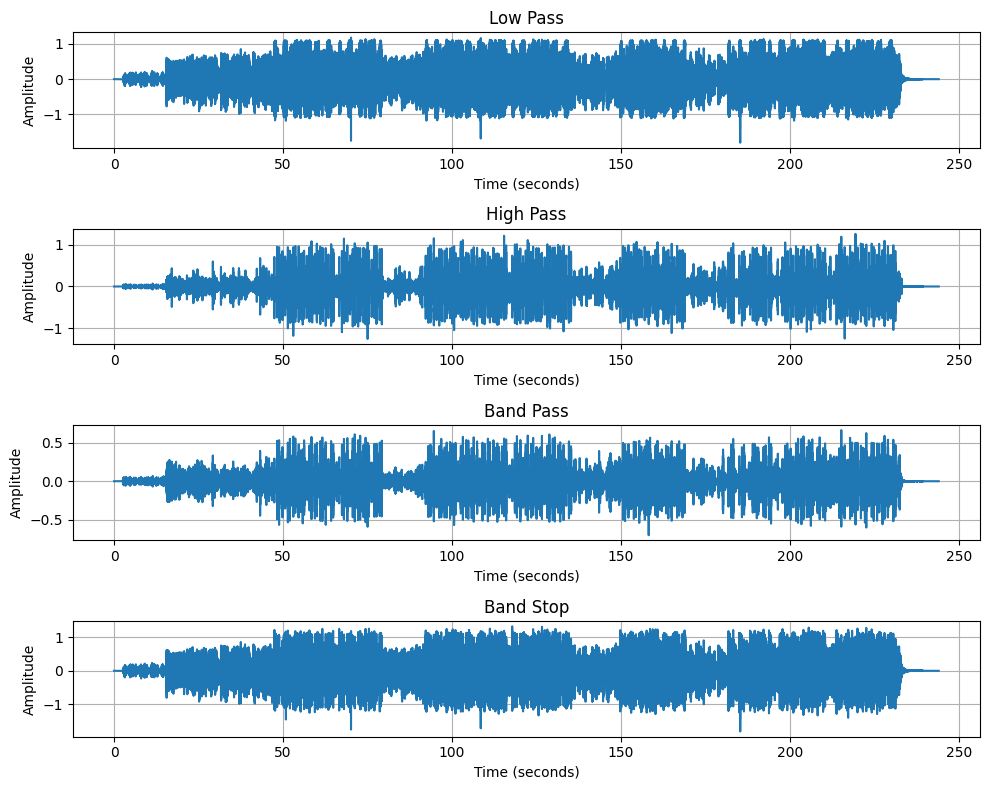

All filtered songs saved!


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
from scipy.io import wavfile
from scipy.signal import firwin, lfilter

song, Fs = librosa.load("Todh___Prince_Narula___Munawar__Official_Video____Jaymeet___Rony_Ajnali___Gill_Machhrai(128k).mp3", sr=None)

N = 31

low = firwin(N, 3000, window='hann', fs=Fs)
high = firwin(N, 3000, window='hann', pass_zero='highpass', fs=Fs)
band = firwin(N, [3000, 6000], window='hann', pass_zero='bandpass', fs=Fs)
stop = firwin(N, [3000, 6000], window='hann', pass_zero='bandstop', fs=Fs)

filters = [low, high, band, stop]
titles = ['Low Pass', 'High Pass', 'Band Pass', 'Band Stop']
files = ['low_pass.wav', 'high_pass.wav', 'band_pass.wav', 'band_stop.wav']

plt.figure(figsize=(10, 8))

for i in range(4):
    output = lfilter(filters[i], 1, song)
    plt.subplot(4, 1, i + 1)
    plt.plot(np.arange(len(output)) / Fs, output)
    plt.title(titles[i])
    plt.xlabel('Time (seconds)')
    plt.ylabel('Amplitude')
    plt.grid()
    wavfile.write(files[i], Fs, (output / (np.max(np.abs(output)) + 1e-10) * 32767).astype(np.int16))

plt.tight_layout()
plt.show()

print("All filtered songs saved!")